# Buổi D1: Kiểm định chéo cho ra lẽ

**Hiện trường.** Chị Hạnh có hai mô hình ứng viên và chỉ **178 ca** dữ liệu (một bộ đo hóa học của rượu vang, ba giống nho). Đồng nghiệp đưa một lần chia 75/25 và nói *"mô hình A hơn B hai điểm"*. Chị hỏi: *"nếu chia lại cách khác thì sao?"*. Dữ liệu ít thế này, mỗi ca trong tập thi nặng ký, và một lần chia có thể may hoặc rủi.

**Mục tiêu:** hiểu **bên trong** kiểm định chéo (đã dùng nhiều ở phần C, giờ mở nắp máy), biết chọn số phần K, biết khi nào phải chia **giữ tỉ lệ nhóm**, và biết **lặp** để phân biệt hai mô hình ngang nhau với hai mô hình khác nhau thật.

**Mindset của người làm dữ liệu:** một con số điểm luôn đi kèm câu hỏi *"nó dao động bao nhiêu nếu làm lại?"*.

**Lưu ý:** dữ liệu mẫu để học, không dùng ra quyết định thật.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: cùng một mô hình, chia khác đi thì điểm dao động bao nhiêu? |
| Chặng 1 | Bên trong kiểm định chéo có gì? Tự viết vòng lặp |
| Chặng 2 | Chọn K thế nào: 3, 5, 10 hay hết sức? |
| Chặng 3 | Khi nhóm hiếm: vì sao phải chia giữ tỉ lệ (stratified)? |
| Chặng 4 | Lặp nhiều lần: hai mô hình khác nhau thật hay chỉ ngang nhau? |
| Chặng 5 | Giới hạn: kiểm định chéo không thay được tập thi |

## Chặng 0: Cùng mô hình, chia khác đi, điểm dao động

**Câu hỏi:** một lần chia cho ta biết điều gì và không biết điều gì?

Ta lấy một mô hình duy nhất (hồi quy logistic có chuẩn hóa), chia 75/25 bằng **40 hạt giống khác nhau**, rồi xem điểm trên tập thi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X, y = load_wine(return_X_y=True, as_frame=True)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
one_split = []
for seed in range(40):
    a, b, c, d = train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)
    one_split.append(model.fit(a, c).score(b, d))
print("shape:", X.shape, "| classes:", np.bincount(y).tolist())
print("min", round(min(one_split), 3), "max", round(max(one_split), 3), "std", round(np.std(one_split), 3))

shape: (178, 13) | classes: [59, 71, 48]
min 0.956 max 1.0 std 0.014


**Giải thích từng dòng**

- `load_wine(return_X_y=True, as_frame=True)`: lấy bảng `X` (13 cột hóa học) và cột `y` (giống nho 0, 1, 2) của 178 mẫu rượu.
- `make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))`: chuỗi chuẩn hóa rồi phân loại (đã học ở C1).
- `for seed in range(40):`: lặp 40 lần, mỗi lần một cách chia khác (`seed` là hạt giống của lần chia).
- `train_test_split(..., stratify=y)`: (đã học ở A4) chia 75/25 giữ tỉ lệ ba giống nho.
- `model.fit(a, c).score(b, d)`: học trên phần học `a, c`, chấm trên phần thi `b, d`.

**Cách đọc.**
- **Con số:** 40 lần chia cho điểm từ **95,6%** đến **100,0%**; độ lệch chuẩn **0,014**.
- **Bức tranh:** tập thi chỉ có khoảng 44 ca, nên mỗi ca sai là mất cỡ **2,3%**. Hai mô hình hơn kém nhau "hai điểm" trên một lần chia gần như nằm trong sai số của chính cách chia.
- **Câu hỏi tiếp:** có cách nào dùng **mọi ca** vừa để học vừa để thi mà không gian lận?

**Mang về chặng 0:** một lần chia cho một con số nhưng không cho biết con số đó chắc đến đâu.

## Chặng 1: Bên trong kiểm định chéo, tự viết vòng lặp

**Câu hỏi:** `cross_val_score` thật sự làm gì?

Đời thường: lớp có 5 nhóm bài. Lần 1 ôn nhóm 2-5, thi nhóm 1. Lần 2 ôn nhóm 1,3-5, thi nhóm 2... Sau 5 lần, **mỗi bài được thi đúng một lần**, và mỗi lần ôn đều không thấy đề thi. Gọi là **kiểm định chéo K phần** (*K-fold*, ở đây K = 5).

Ta tự viết vòng lặp đó trong sáu dòng.

In [3]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=0)
manual = []
for fold, (tr, te) in enumerate(kf.split(X), start=1):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    m.fit(X.iloc[tr], y.iloc[tr])
    manual.append(m.score(X.iloc[te], y.iloc[te]))
    print("fold", fold, "| train", len(tr), "| test", len(te), "| score", round(manual[-1], 3))
print("mean:", round(np.mean(manual), 3))

fold 1 | train 142 | test 36 | score 1.0
fold 2 | train 142 | test 36 | score 0.972
fold 3 | train 142 | test 36 | score 0.972
fold 4 | train 143 | test 35 | score 1.0
fold 5 | train 143 | test 35 | score 1.0
mean: 0.989


**Giải thích từng dòng**

- `KFold(n_splits=5, shuffle=True, random_state=0)`: bộ cắt dữ liệu thành 5 phần. `shuffle=True` xáo trước khi cắt (nếu dữ liệu xếp theo nhóm thì không xáo sẽ rất tệ). `random_state` cố định cách xáo.
- `kf.split(X)`: mỗi vòng trả về hai danh sách **vị trí dòng**: dòng để học (`tr`) và dòng để thi (`te`).
- `enumerate(..., start=1)`: đánh số vòng bắt đầu từ 1 cho dễ đọc.
- `X.iloc[tr]`: lấy các dòng theo **vị trí** (`iloc`, đã gặp ở A2).
- `m = make_pipeline(...)`: dựng mô hình **mới tinh** mỗi vòng để vòng sau không thừa hưởng gì của vòng trước.

same as the manual loop: True


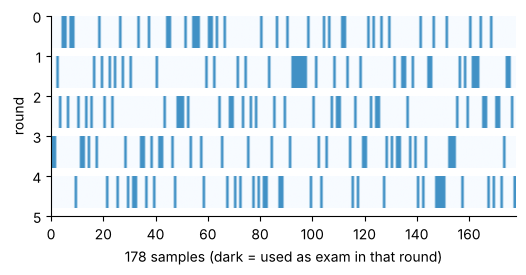

In [4]:
from sklearn.model_selection import cross_val_score
auto = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, y, cv=kf)
print("same as the manual loop:", np.allclose(auto, manual))
fig, ax = plt.subplots(figsize=(6, 2.6))
for i, (tr, te) in enumerate(kf.split(X)):
    row = np.zeros(len(X)); row[te] = 1
    ax.imshow(row[None, :], extent=[0, len(X), i, i + 0.8], cmap="Blues", aspect="auto", vmin=0, vmax=1.6)
ax.set_ylim(5, 0); ax.set_xlabel("178 samples (dark = used as exam in that round)"); ax.set_ylabel("round")
plt.show()

**Giải thích từng dòng**

- `cross_val_score(pipe, X, y, cv=kf)`: hàm làm cả vòng lặp trên giúp ta. Truyền `cv=kf` để dùng đúng cách cắt vừa tạo.
- `np.allclose(auto, manual)`: kiểm tra hai danh sách điểm trùng nhau (so số thực nên dùng `allclose`, không dùng `==`).
- `ax.imshow(...)`: vẽ mỗi vòng một dải; ô đậm là những dòng làm đề thi vòng đó. Đây là hình trang trí, chỉ cần chạy.

**Cách đọc.**
- **Con số:** năm điểm 1,000, 0,972, 0,972, 1,000, 1,000; trung bình **0,989**. Hàm có sẵn cho đúng kết quả của vòng tự viết: **True**.
- **Bức tranh:** mỗi ca làm đề thi đúng **một** lần và làm bài học bốn lần. Ta dùng hết dữ liệu mà không có ca nào vừa học vừa thi trong cùng vòng.
- **Câu hỏi tiếp:** vì sao 5 mà không phải 3 hay 20?

**Mang về chặng 1:** kiểm định chéo chỉ là vòng lặp "chia, học, thi, ghi điểm" lặp K lần với mô hình mới mỗi vòng.

## Chặng 2: Chọn K thế nào

**Câu hỏi:** K lớn hay nhỏ thì sao?

- **K nhỏ (3):** mỗi vòng học trên ít dữ liệu hơn nên điểm hơi **thấp hơn thực tế**, nhưng chạy nhanh.
- **K lớn (20, hoặc bằng số ca):** học gần hết dữ liệu nên điểm sát thực tế hơn, nhưng **chạy lâu** và các vòng giống nhau nên điểm các phần dính nhau.
- **K = số ca** gọi là **bỏ một** (*leave-one-out*): mỗi lần thi đúng một ca.

Ta đo điểm trung bình, độ lệch và thời gian cho nhiều K, chạy lặp để ổn định.

In [5]:
import time
from sklearn.model_selection import RepeatedStratifiedKFold, LeaveOneOut
rows = []
for k in [2, 3, 5, 10, 20]:
    t0 = time.time()
    cv = RepeatedStratifiedKFold(n_splits=k, n_repeats=5, random_state=0)
    s = cross_val_score(model, X, y, cv=cv)
    rows.append({"K": k, "mean": s.mean(), "std_of_folds": s.std(), "seconds": time.time() - t0})
t0 = time.time()
loo = cross_val_score(model, X, y, cv=LeaveOneOut())
rows.append({"K": "LOO (178)", "mean": loo.mean(), "std_of_folds": loo.std(), "seconds": time.time() - t0})
res_k = pd.DataFrame(rows)
print(res_k.round(3).to_string(index=False))

        K  mean  std_of_folds  seconds
        2 0.979         0.012    0.137
        3 0.980         0.015    0.217
        5 0.982         0.017    0.320
       10 0.983         0.028    0.632
       20 0.981         0.042    1.322
LOO (178) 0.983         0.129    2.432


**Giải thích từng dòng**

- `RepeatedStratifiedKFold(n_splits=k, n_repeats=5, ...)`: lặp K-fold 5 lần với cách xáo khác nhau, giữ tỉ lệ nhóm (đã dùng ở phần C). Dùng để số liệu ít nhiễu hơn.
- `LeaveOneOut()`: mỗi vòng thi đúng một ca, học trên 177 ca còn lại: 178 vòng.
- `time.time()`: đồng hồ bấm giờ (giây). Hiệu hai lần gọi là thời gian chạy.
- `s.std()`: độ lệch chuẩn của điểm các phần. Với LOO mỗi điểm chỉ là 0 hoặc 1 nên độ lệch này không có nhiều ý nghĩa.

**Cách đọc.**
- **Con số:** điểm trung bình dao động trong khoảng **0,979** đến **0,983** giữa các K; thời gian từ **0,12** s đến **2,01** s.
- **Bức tranh:** với dữ liệu nhỏ, mọi K hợp lý cho điểm gần nhau; K càng lớn càng tốn thời gian. Chênh lệch giữa các K nhỏ hơn nhiều so với độ dao động của một lần chia ở chặng 0.
- **Thực tế:** **K = 5 hoặc 10** là lựa chọn mặc định hợp lý. Dữ liệu rất ít thì tăng K hoặc lặp nhiều lần; dữ liệu rất lớn thì K = 3 đã đủ.
- **Câu hỏi tiếp:** chuyện gì xảy ra khi một nhóm rất hiếm?

**Mang về chặng 2:** K = 5 hoặc 10 là mặc định; đổi K ít thay đổi kết luận, còn lặp nhiều lần mới giảm nhiễu.

## Chặng 3: Khi nhóm hiếm, phải chia giữ tỉ lệ

**Câu hỏi:** nếu chia ngẫu nhiên, một phần có thể vô tình thiếu hẳn nhóm hiếm?

Ta dựng tình huống hiếm: 357 ca lành tính và chỉ **20 ca ác tính** (dữ liệu tự dựng có chủ đích từ bộ ung thư vú). Chia 10 phần, đếm số ca ác tính **trong từng phần thi**.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold
bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, 1 - bc.target
rng = np.random.RandomState(0)
keep = np.sort(np.concatenate([np.where(yb == 0)[0], rng.choice(np.where(yb == 1)[0], 20, replace=False)]))
Xr, yr = Xb.iloc[keep], yb.iloc[keep]
plain = [int(yr.iloc[te].sum()) for _, te in KFold(10, shuffle=True, random_state=1).split(Xr)]
strat = [int(yr.iloc[te].sum()) for _, te in StratifiedKFold(10, shuffle=True, random_state=1).split(Xr, yr)]
print("malignant per exam fold, plain KFold:     ", plain)
print("malignant per exam fold, StratifiedKFold: ", strat)

malignant per exam fold, plain KFold:      [4, 1, 2, 4, 2, 2, 0, 2, 2, 1]
malignant per exam fold, StratifiedKFold:  [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


**Giải thích từng dòng**

- `np.where(yb == 0)[0]`: vị trí các ca lành tính.
- `rng.choice(..., 20, replace=False)`: chọn 20 ca ác tính ngẫu nhiên, không trùng.
- `KFold(10, ...).split(Xr)`: chia 10 phần **không nhìn nhãn**.
- `StratifiedKFold(10, ...).split(Xr, yr)`: chia 10 phần **có nhìn nhãn `yr`** để mỗi phần có tỉ lệ nhóm giống tổng thể. Vì vậy `split` nhận thêm `yr`.
- `int(yr.iloc[te].sum())`: đếm số ca ác tính (nhãn 1) trong phần thi.

**Cách đọc.**
- **Con số:** KFold thường cho số ca ác tính mỗi phần thi: [4, 1, 2, 4, 2, 2, 0, 2, 2, 1]; StratifiedKFold: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2].
- **Bức tranh:** chia thường có phần chỉ có 0 ca ác tính. Phần như vậy cho recall **vô nghĩa hoặc không tính được**, và điểm giữa các phần lệch nhau rất mạnh. Chia giữ tỉ lệ cho mỗi phần đúng khoảng 2 ca, nhờ đó các điểm so sánh được với nhau.
- **Quy tắc:** bài toán **phân loại** thì mặc định dùng `StratifiedKFold`. `cross_val_score` tự làm vậy khi bạn đưa `cv=5` cho một bộ phân loại; nhưng khi đưa `KFold` thì không.
- **Câu hỏi tiếp:** hai mô hình điểm gần nhau, ai thắng?

**Mang về chặng 3:** phân loại thì chia giữ tỉ lệ; nhóm càng hiếm càng quan trọng.

## Chặng 4: Lặp nhiều lần, hai mô hình khác nhau thật hay chỉ ngang nhau?

**Câu hỏi:** mô hình A (hồi quy logistic) và B (k láng giềng, k=5) điểm sát nhau. Kết luận "A hơn B" dựa trên **một** lần kiểm định chéo có đáng tin không?

Thí nghiệm: lặp **40 lần**, mỗi lần chạy kiểm định chéo 5 phần với một cách xáo khác, ghi xem lần đó **A hay B cao hơn**.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
A = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
B = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
diffs = []
for seed in range(40):
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)
    diffs.append(cross_val_score(A, X, y, cv=cv).mean() - cross_val_score(B, X, y, cv=cv).mean())
diffs = np.array(diffs)
print("A better in", int((diffs > 0).sum()), "of 40 runs | B better in", int((diffs < 0).sum()), "| tie", int((diffs == 0).sum()))
print("mean diff (A-B):", round(diffs.mean(), 4), "| std of diff:", round(diffs.std(), 4))

A better in 38 of 40 runs | B better in 2 | tie 0
mean diff (A-B): 0.0167 | std of diff: 0.0097


**Giải thích từng dòng**

- `A = make_pipeline(...)`: mô hình A và B, mỗi mô hình nằm trong một chuỗi chuẩn hóa. k-NN rất cần chuẩn hóa (đã học ở C3).
- `cv = StratifiedKFold(5, shuffle=True, random_state=seed)`: mỗi lần lặp dùng **cùng một cách chia cho cả hai mô hình** để so sánh công bằng, nhưng khác nhau giữa các lần lặp.
- `cross_val_score(A, ...).mean() - cross_val_score(B, ...).mean()`: hiệu điểm trung bình của hai mô hình trong cùng cách chia.
- `(diffs > 0).sum()`: đếm số lần A cao hơn. Biểu thức `diffs > 0` cho dãy đúng/sai; `.sum()` đếm số đúng.

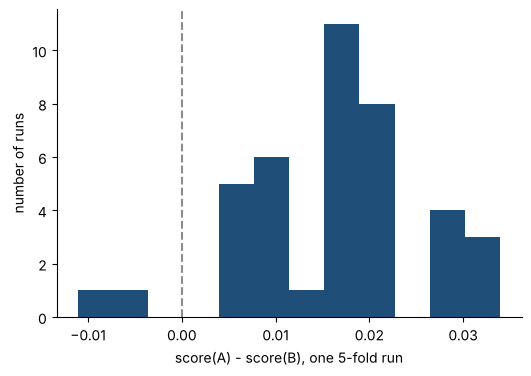

In [8]:
plt.hist(diffs, bins=12, color=BLUE)
plt.axvline(0, color=GRAY, linestyle="--")
plt.xlabel("score(A) - score(B), one 5-fold run")
plt.ylabel("number of runs")
plt.show()

**Giải thích từng dòng**

- `plt.axvline(0, ...)`: vạch đứng tại 0: bên phải là A hơn, bên trái là B hơn.

**Cách đọc.**
- **Con số:** A cao hơn trong **38/40** lần chạy, B cao hơn trong **2/40**; chênh trung bình **1,67** điểm phần trăm, độ lệch của chênh lệch **0,97** điểm phần trăm.
- **Bức tranh:** nếu chênh trung bình lớn hơn nhiều độ lệch của nó thì A thắng ổn định; nếu cùng cỡ thì kết luận "ai hơn" chỉ phụ thuộc vào cách xáo của lần chạy. Hãy đối chiếu hai con số trên để biết bài này thuộc trường hợp nào.
- **Quy tắc thực tế:** hai mô hình hơn kém nhau **nhỏ hơn độ dao động** thì xem như **ngang nhau** và chọn mô hình **đơn giản, dễ giải thích** hơn. Lặp kiểm định chéo (như `RepeatedStratifiedKFold`) làm con số ổn định hơn, nhưng không biến một chênh lệch rất nhỏ thành một lợi thế thật.

**Mang về chặng 4:** so hai mô hình trên cùng cách chia, lặp nhiều lần, và đối chiếu chênh lệch với độ dao động của nó.

## Chặng 5: Giới hạn, kiểm định chéo không thay được tập thi

**Câu hỏi:** nếu kiểm định chéo đã thi mọi ca, còn cần tập thi niêm phong nữa không?

Cần, vì ta **dùng điểm kiểm định chéo để chọn** (mô hình nào, tham số nào). Càng chọn nhiều thì điểm "cao nhất" càng có phần may mắn. Ví dụ: thử 200 mô hình **vô nghĩa** (đoán mò trên nhãn đã xáo) và lấy điểm kiểm định chéo cao nhất.

In [9]:
rng = np.random.RandomState(7)
y_shuffled = pd.Series(rng.permutation(y.values), index=y.index)
best = []
for i in range(200):
    cols = rng.choice(X.columns, size=3, replace=False)
    best.append(cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)), X[cols], y_shuffled, cv=5).mean())
print("true chance level ~", round(1 / 3, 3))
print("average over 200 useless models:", round(np.mean(best), 3), "| best of them:", round(max(best), 3))

true chance level ~ 0.333
average over 200 useless models: 0.377 | best of them: 0.438


**Giải thích từng dòng**

- `rng.permutation(y.values)`: xáo thứ tự nhãn: mối liên hệ thật giữa cột và nhãn bị phá, mọi mô hình giờ chỉ là đoán mò.
- `rng.choice(X.columns, size=3, replace=False)`: mỗi 'mô hình' dùng 3 cột ngẫu nhiên.
- `max(best)`: chọn điểm cao nhất trong 200 lần thử, giống một người chọn 'mô hình tốt nhất' sau khi thử rất nhiều.

**Cách đọc.**
- **Con số:** mức đoán mò khoảng **0,33**; trung bình 200 mô hình vô nghĩa **0,377**, nhưng mô hình "tốt nhất" trong đó đạt **0,438**.
- **Bức tranh:** thử càng nhiều, điểm tốt nhất càng vượt trên mức đoán mò dù mọi mô hình đều vô dụng. Đó là lý do ta phải giữ **tập thi niêm phong** cho lần chấm cuối: nó chưa tham gia cuộc thi tuyển chọn nên không bị "may mắn" thổi phồng.
- **Câu hỏi tiếp:** khi thử rất nhiều tham số (buổi D4), điều này còn nguy hiểm hơn. Trước đó, buổi D2 sẽ cho thấy cách nhìn một mô hình đang học vẹt hay học chưa đủ.

**Mang về chặng 5:** kiểm định chéo để chọn, tập thi niêm phong để báo cáo; chọn càng nhiều thì điểm cao nhất càng bị thổi phồng.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Một lần chia cho một con số nhưng không cho biết nó chắc đến đâu. |
| 1 | Kiểm định chéo = vòng lặp chia, học, thi, ghi điểm, mô hình mới mỗi vòng. |
| 2 | K = 5 hoặc 10 là mặc định; đổi K ít đổi kết luận. |
| 3 | Phân loại thì chia giữ tỉ lệ nhóm (`StratifiedKFold`). |
| 4 | So mô hình trên cùng cách chia, lặp nhiều lần; chênh nhỏ hơn dao động thì xem là ngang nhau. |
| 5 | Chọn bằng kiểm định chéo, báo cáo bằng tập thi niêm phong. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Chia lớp thành 5 nhóm bài, lần lượt thi mỗi nhóm | kiểm định chéo K phần | `KFold`, `cross_val_score` |
| Mỗi vòng dùng một mô hình mới tinh | tránh rò rỉ giữa các vòng | `make_pipeline(...)` trong vòng lặp |
| Thi từng ca một | bỏ một (leave-one-out) | `LeaveOneOut` |
| Chia sao cho phần nào cũng có đủ nhóm hiếm | chia giữ tỉ lệ | `StratifiedKFold` |
| Thi lại nhiều lần với cách xáo khác | kiểm định chéo lặp | `RepeatedStratifiedKFold` |
| Hiệu điểm hai mô hình trên cùng cách chia | so sánh cặp đôi | `diffs` |
| Thử nhiều, lấy điểm cao nhất, tưởng là giỏi | lạc quan do chọn lọc | `max(best)` |

**Thử thách tự làm**

1. Ở chặng 0, đổi `test_size` thành 0.5 rồi 0.1. Độ dao động của điểm đổi thế nào? Vì sao?
2. Ở chặng 2, thêm `n_repeats=20` cho K=5. Điểm trung bình đổi không? Độ ổn định đổi thế nào so với n_repeats=5?
3. Ở chặng 4, thay k-NN bằng k=15. Chênh lệch giữa A và B có còn nằm trong độ dao động không?
4. Ở chặng 5, tăng số mô hình vô nghĩa từ 200 lên 1000. Điểm tốt nhất thay đổi ra sao?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tự viết được vòng lặp K-fold và giải thích từng bước.
- [ ] Chọn K hợp lý theo kích thước dữ liệu.
- [ ] Giải thích vì sao phân loại cần chia giữ tỉ lệ.
- [ ] Nói được khi nào hai mô hình xem là ngang nhau.
- [ ] Giải thích vì sao vẫn cần tập thi niêm phong sau kiểm định chéo.

## Phần thưởng (Tip pro): Bẫy của K-fold khi dữ liệu có thứ tự hoặc có nhóm


`KFold(shuffle=False)` cắt dữ liệu theo thứ tự dòng. Nếu bảng xếp theo nhóm (như `load_wine` xếp theo giống nho, hoặc dữ liệu theo thời gian), mỗi phần thi sẽ chỉ chứa **một nhóm** và điểm sẽ tệ hoặc vô nghĩa. Còn nếu cùng một người (hay cùng một khách hàng) xuất hiện ở nhiều dòng, chia ngẫu nhiên sẽ để ca của người đó nằm ở cả học lẫn thi, điểm đẹp một cách giả tạo. Cả hai trường hợp được xử lý ở buổi D6 (chia theo nhóm và theo thời gian).